# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Objective:** Analyse monthly rainfall in Kampala, Gulu and Mbarara, compare rainfall patterns, classify crop suitability and advise farmers.

The rainfall values are illustrative data supplied in the assignment.

In [3]:
import os
import importlib
import src.rainfall as rainfall

print("Current directory:", os.getcwd())
print("Imported file:", rainfall.__file__)
print("Has Region:", hasattr(rainfall, "Region"))
print("Available names:", [
    name for name in dir(rainfall)
    if not name.startswith("_")
])

Current directory: c:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\Assignment1-OOP\project4_rainfall.crop
Imported file: c:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\Assignment1-OOP\project4_rainfall.crop\src\rainfall.py
Has Region: False
Available names: []


In [ ]:
from pathlib import Path
import importlib
import sys

project = Path.cwd().resolve()
module_file = project / "src" / "rainfall.py"

print("Project directory:", project)
print("rainfall.py exists:", module_file.exists())

if module_file.exists():
    print("Contains class definition:",
          "class Region" in module_file.read_text(encoding="utf-8"))

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import src.rainfall as rainfall

importlib.invalidate_caches()
importlib.reload(rainfall)

print("Module loaded from:", rainfall.__file__)
print("Region available:", hasattr(rainfall, "Region"))

Project directory: C:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\Assignment1-OOP\project4_rainfall.crop
rainfall.py exists: True
Contains class definition: True


In [1]:
from src.rainfall import (
    Region,
    CropRule,
    MONTHS,
    cosine_similarity,
    compare_regions,
)

print("Import successful!")

Import successful!


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cosine
from src.rainfall import Region, CropRule, MONTHS, cosine_similarity

data = {
    "Kampala": [120, 140, 180, 200, 220, 180,
                90, 70, 60, 100, 110, 130],
    "Gulu": [8, 25, 75, 160, 190, 145,
             170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25,
                20, 55, 100, 125, 120, 90]
}

regions = {
    name: Region(name, rainfall)
    for name, rainfall in data.items()
}

In [4]:
summary = pd.DataFrame({
    name: {
        "Annual total (mm)": r.annual_total(),
        "Monthly mean (mm)": r.mean(),
        "Wettest month": r.wettest_month(),
        "Driest month": r.driest_month(),
        "Coefficient of variation": r.coefficient_of_variation()
    }
    for name, r in regions.items()
}).T

summary.round(2)

,Annual total (mm),Monthly mean (mm),Wettest month,Driest month,Coefficient of variation
Kampala,1600.0,133.333333,May,Sep,37.165172
Gulu,1388.0,115.666667,Aug,Jan,61.422171
Mbarara,1040.0,86.666667,Apr,Jul,42.482158


In [5]:

crops = [
    CropRule("maize", 40, 150),
    CropRule("beans", 30, 120),
    CropRule("coffee", 60, 180)
]

rows = []

for name, region in regions.items():
    for month, rain in zip(MONTHS, region.rainfall):
        for crop in crops:
            rows.append({
                "Region": name,
                "Month": month,
                "Rainfall (mm)": rain,
                "Crop": crop.name,
                "Classification": crop.classify(float(rain))
            })

crop_results = pd.DataFrame(rows)
crop_results

,Region,Month,Rainfall (mm),Crop,Classification
0,Kampala,Jan,120.0,maize,Good for maize
1,Kampala,Jan,120.0,beans,Good for beans
2,Kampala,Jan,120.0,coffee,Good for coffee
3,Kampala,Feb,140.0,maize,Good for maize
4,Kampala,Feb,140.0,beans,Waterlogging risk
...,...,...,...,...,...
103,Mbarara,Nov,120.0,beans,Good for beans
104,Mbarara,Nov,120.0,coffee,Good for coffee
105,Mbarara,Dec,90.0,maize,Good for maize
106,Mbarara,Dec,90.0,beans,Good for beans


In [7]:
kampala = regions["Kampala"].rainfall
gulu = regions["Gulu"].rainfall

my_similarity = cosine_similarity(kampala, gulu)

# SciPy cosine() returns distance, not similarity.
scipy_similarity = 1 - cosine(kampala, gulu)

print("NumPy cosine similarity:", round(my_similarity, 4))
print("SciPy cosine similarity:", round(scipy_similarity, 4))

assert np.isclose(my_similarity, scipy_similarity)
print("Verification successful.")

NumPy cosine similarity: 0.7866
SciPy cosine similarity: 0.7866
Verification successful.


In [8]:
names = list(regions)
n = len(names)

cosine_matrix = np.eye(n)
pearson_matrix = np.eye(n)
euclidean_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):
        a = regions[names[i]].rainfall
        b = regions[names[j]].rainfall

        cos_value = cosine_similarity(a, b)
        corr_value = np.corrcoef(a, b)[0, 1]
        distance_value = np.linalg.norm(a - b)

        cosine_matrix[i, j] = cosine_matrix[j, i] = cos_value
        pearson_matrix[i, j] = pearson_matrix[j, i] = corr_value
        euclidean_matrix[i, j] = euclidean_matrix[j, i] = distance_value

print("COSINE SIMILARITY")
display(pd.DataFrame(cosine_matrix, index=names, columns=names).round(3))

print("PEARSON CORRELATION")
display(pd.DataFrame(pearson_matrix, index=names, columns=names).round(3))

print("EUCLIDEAN DISTANCE (mm)")
display(pd.DataFrame(euclidean_matrix, index=names, columns=names).round(2))

COSINE SIMILARITY


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


PEARSON CORRELATION


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


EUCLIDEAN DISTANCE (mm)


,Kampala,Gulu,Mbarara
Kampala,0.00,315.27,250.4
Gulu,315.27,0.00,312.8
Mbarara,250.40,312.80,0.0


In [9]:
for name, region in regions.items():
    peaks = region.rainy_seasons()

    print("Region:", name)
    print("Peak months:", peaks)
    print("Pattern:", region.season_pattern())
    print()

Region: Kampala
Peak months: ['May']
Pattern: Unimodal

Region: Gulu
Peak months: ['May', 'Aug']
Pattern: Bimodal

Region: Mbarara
Peak months: ['Apr', 'Oct']
Pattern: Bimodal



In [10]:
class CropRule:
    """Classify monthly rainfall against a crop's screening thresholds."""

    def __init__(
        self,
        crop_name: str,
        minimum_mm: float,
        maximum_mm: float
    ) -> None:
        """
        Set monthly rainfall thresholds.

        Rainfall below minimum is classified as drought risk.
        Rainfall above maximum is classified as waterlogging risk.
        """
        if not crop_name.strip():
            raise ValueError("Crop name cannot be empty.")
        if minimum_mm < 0 or maximum_mm <= minimum_mm:
            raise ValueError("Invalid rainfall thresholds.")

        self.crop_name = crop_name
        self.minimum_mm = minimum_mm
        self.maximum_mm = maximum_mm

    def classify(self, rainfall_mm: float) -> str:
        """Return a monthly rainfall screening classification."""
        if not np.isfinite(rainfall_mm) or rainfall_mm < 0:
            raise ValueError("Rainfall must be finite and non-negative.")

        if rainfall_mm < self.minimum_mm:
            return "Drought risk"
        elif rainfall_mm > self.maximum_mm:
            return "Waterlogging risk"
        return f"Good for {self.crop_name}"

    def __repr__(self) -> str:
        """Return a concise description of the crop rule."""
        return (
            f"CropRule({self.crop_name!r}, "
            f"{self.minimum_mm}, {self.maximum_mm})"
        )


# Illustrative monthly rainfall screening thresholds (mm/month).
crop_rules = {
    "Maize": CropRule("maize", 80, 200),
    "Beans": CropRule("beans", 75, 150),
    "Coffee": CropRule("coffee", 100, 180),
}

print(crop_rules)

{'Maize': CropRule('maize', 80, 200), 'Beans': CropRule('beans', 75, 150), 'Coffee': CropRule('coffee', 100, 180)}


In [11]:
classification_records = []

for region_name, region in regions.items():
    for crop_name, rule in crop_rules.items():
        for month, rainfall in zip(MONTHS, region.rainfall):
            classification_records.append({
                "Region": region_name,
                "Month": month,
                "Rainfall (mm)": rainfall,
                "Crop": crop_name,
                "Classification": rule.classify(float(rainfall)),
            })

suitability_df = pd.DataFrame(classification_records)

display(
    suitability_df[
        suitability_df["Region"] == "Kampala"
    ].pivot(
        index="Month",
        columns="Crop",
        values="Classification"
    )
)

print("All monthly classifications:", len(suitability_df))

Crop,Beans,Coffee,Maize
Month,,,
Apr,Waterlogging risk,Waterlogging risk,Good for maize
Aug,Drought risk,Drought risk,Drought risk
Dec,Good for beans,Good for coffee,Good for maize
Feb,Good for beans,Good for coffee,Good for maize
Jan,Good for beans,Good for coffee,Good for maize
Jul,Good for beans,Drought risk,Good for maize
Jun,Waterlogging risk,Good for coffee,Good for maize
Mar,Waterlogging risk,Good for coffee,Good for maize
May,Waterlogging risk,Waterlogging risk,Waterlogging risk


All monthly classifications: 108


In [12]:
def cosine_similarity(
    x: np.ndarray,
    y: np.ndarray
) -> float:
    """Calculate cosine similarity between two non-zero vectors."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("Inputs must be one-dimensional.")
    if x.shape != y.shape:
        raise ValueError("Vectors must have equal lengths.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Vectors must contain finite values.")

    denominator = np.linalg.norm(x) * np.linalg.norm(y)

    if denominator == 0:
        raise ValueError("Cosine similarity is undefined for zero vectors.")

    return float(np.dot(x, y) / denominator)


x = regions["Kampala"].rainfall
y = regions["Gulu"].rainfall

numpy_similarity = cosine_similarity(x, y)
scipy_similarity = 1 - cosine(x, y)

print(f"NumPy cosine similarity: {numpy_similarity:.6f}")
print(f"SciPy cosine similarity: {scipy_similarity:.6f}")

assert np.isclose(numpy_similarity, scipy_similarity)
print("Verification passed.")

NumPy cosine similarity: 0.786609
SciPy cosine similarity: 0.786609
Verification passed.


In [14]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

region_names = list(regions.keys())

cosine_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)
pearson_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)
euclidean_matrix = pd.DataFrame(
    index=region_names, columns=region_names, dtype=float
)

for name_a in region_names:
    for name_b in region_names:
        a = regions[name_a].rainfall
        b = regions[name_b].rainfall

        cosine_matrix.loc[name_a, name_b] = cosine_similarity(a, b)

        if np.std(a) == 0 or np.std(b) == 0:
            pearson_value = np.nan
        else:
            pearson_value = pearsonr(a, b).statistic

        pearson_matrix.loc[name_a, name_b] = pearson_value
        euclidean_matrix.loc[name_a, name_b] = np.linalg.norm(a - b)

print("COSINE SIMILARITY")
display(cosine_matrix.round(3))

print("PEARSON CORRELATION")
display(pearson_matrix.round(3))

print("EUCLIDEAN DISTANCE (mm)")
display(euclidean_matrix.round(2))

COSINE SIMILARITY


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


PEARSON CORRELATION


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


EUCLIDEAN DISTANCE (mm)


,Kampala,Gulu,Mbarara
Kampala,0.00,315.27,250.4
Gulu,315.27,0.00,312.8
Mbarara,250.40,312.80,0.0


In [16]:
import numpy as np
from scipy.signal import find_peaks

def detect_rainy_seasons(
    rainfall: np.ndarray,
    prominence: float = 30,
    minimum_distance: int = 2
) -> dict:
    """
    Detect prominent monthly rainfall peaks.

    Returns peak indices, month labels, and a simple peak-count
    classification. This is a screening method, not a formal
    meteorological season detector.
    """
    rainfall = np.asarray(rainfall, dtype=float)

    if rainfall.shape != (12,):
        raise ValueError("Expected 12 monthly rainfall values.")
    if not np.all(np.isfinite(rainfall)) or np.any(rainfall < 0):
        raise ValueError("Rainfall must be finite and non-negative.")
    if prominence < 0 or minimum_distance < 1:
        raise ValueError("Invalid peak detection parameters.")

    peaks, properties = find_peaks(
        rainfall,
        prominence=prominence,
        distance=minimum_distance
    )

    if len(peaks) == 1:
        pattern = "Unimodal"
    elif len(peaks) >= 2:
        pattern = "Bimodal/multiple peaks"
    else:
        pattern = "No prominent peak detected"

    return {
        "peak_indices": peaks,
        "peak_months": [MONTHS[i] for i in peaks],
        "peak_values_mm": rainfall[peaks].tolist(),
        "pattern": pattern,
    }


season_results = {}

for name, region in regions.items():
    result = detect_rainy_seasons(region.rainfall)
    season_results[name] = result

    print(f"\n{name}")
    print("Peak months:", result["peak_months"])
    print("Peak rainfall (mm):", result["peak_values_mm"])
    print("Classification:", result["pattern"])


Kampala
Peak months: ['May']
Peak rainfall (mm): [220.0]
Classification: Unimodal

Gulu
Peak months: ['May', 'Aug']
Peak rainfall (mm): [190.0, 215.0]
Classification: Bimodal/multiple peaks

Mbarara
Peak months: ['Apr', 'Oct']
Peak rainfall (mm): [140.0, 125.0]
Classification: Bimodal/multiple peaks


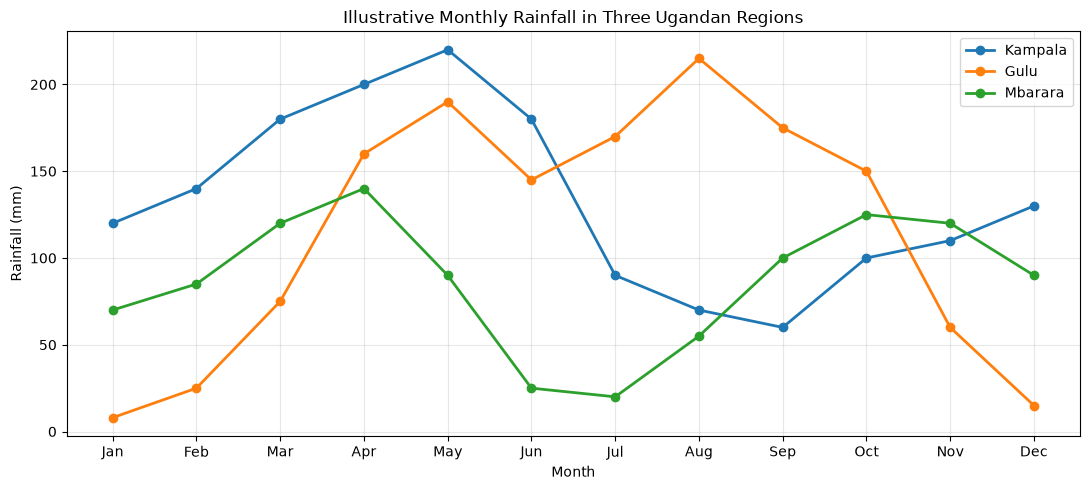

In [17]:
plt.figure(figsize=(11, 5))

for name, region in regions.items():
    plt.plot(
        MONTHS,
        region.rainfall,
        marker="o",
        linewidth=2,
        label=name
    )

plt.title("Illustrative Monthly Rainfall in Three Ugandan Regions")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

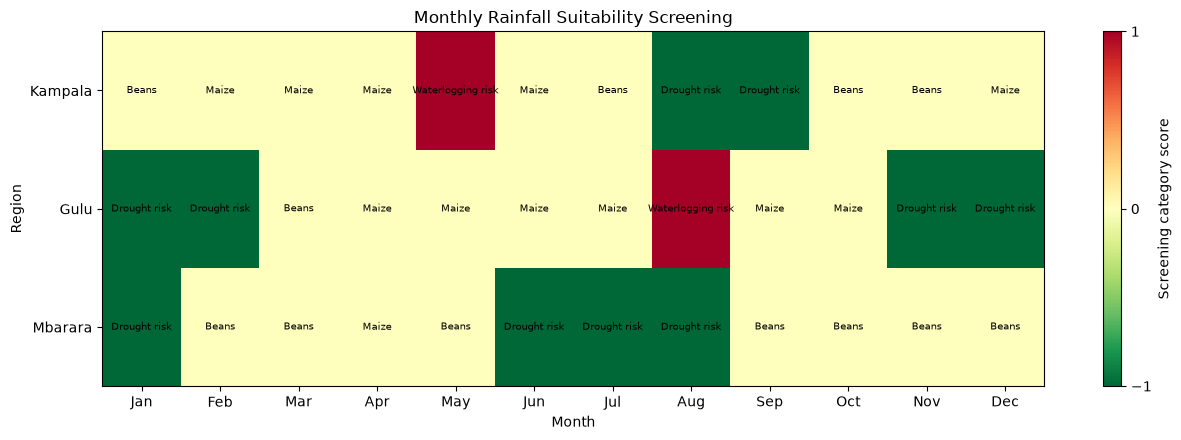

In [18]:
crop_names = list(crop_rules.keys())

# Rows = regions, columns = months
heatmap_values = np.zeros((len(region_names), 12))
heatmap_labels = np.empty((len(region_names), 12), dtype=object)

for i, region_name in enumerate(region_names):
    rainfall = regions[region_name].rainfall

    for j, value in enumerate(rainfall):
        good_crops = [
            (crop_name, rule)
            for crop_name, rule in crop_rules.items()
            if rule.minimum_mm <= value <= rule.maximum_mm
        ]

        if good_crops:
            crop_name, _ = min(
                good_crops,
                key=lambda item: abs(
                    value - (
                        item[1].minimum_mm + item[1].maximum_mm
                    ) / 2
                )
            )
            heatmap_values[i, j] = 0
            heatmap_labels[i, j] = crop_name
        elif value < min(rule.minimum_mm for rule in crop_rules.values()):
            heatmap_values[i, j] = -1
            heatmap_labels[i, j] = "Drought risk"
        else:
            heatmap_values[i, j] = 1
            heatmap_labels[i, j] = "Waterlogging risk"

fig, ax = plt.subplots(figsize=(13, 4.5))

im = ax.imshow(
    heatmap_values,
    cmap="RdYlGn_r",
    aspect="auto",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS)
ax.set_yticks(range(len(region_names)))
ax.set_yticklabels(region_names)

for i in range(len(region_names)):
    for j in range(12):
        ax.text(
            j, i, heatmap_labels[i, j],
            ha="center", va="center", fontsize=7
        )

ax.set_title("Monthly Rainfall Suitability Screening")
ax.set_xlabel("Month")
ax.set_ylabel("Region")

fig.colorbar(
    im,
    ax=ax,
    ticks=[-1, 0, 1],
    label="Screening category score"
)

plt.tight_layout()
plt.show()

In [22]:
import os
print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

Current folder: c:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\Assignment1-OOP\project4_rainfall.crop
Files in folder: ['.venv', 'rainfall_crop.ipynb', 'src']


In [25]:
import numpy as np
import importlib
import rainfall

importlib.reload(rainfall)

from rainfall import (
    Region,
    CropRule,
    cosine_similarity,
    compare_regions
)

print("Rainfall module imported successfully!")

Rainfall module imported successfully!


In [26]:
rainfall_data = [
    20, 35, 80, 120, 90, 50,
    30, 25, 40, 100, 70, 35
]

region = Region("Kampala", rainfall_data)

print("Annual rainfall:", region.annual_total(), "mm")
print("Mean monthly rainfall:", region.mean(), "mm")
print("Wettest month:", region.wettest_month())
print("Rainy seasons:", region.rainy_seasons())

Annual rainfall: 695.0 mm
Mean monthly rainfall: 57.916666666666664 mm
Wettest month: Apr
Rainy seasons: ['Apr', 'Oct']


In [ ]:

import numpy as np
import importlib
import rainfall

importlib.reload(rainfall)

from rainfall import (
    Region,
    CropRule,
    cosine_similarity,
    detect_rainy_seasons,
)

# Run the season detection test
monthly_rainfall = np.array([10, 20, 40, 100, 40, 20,
                             10, 20, 40, 90, 40, 20])

result = detect_rainy_seasons(monthly_rainfall, prominence=30)
print("Detected peak indices:", result["peak_indices"])
assert len(result["peak_indices"]) == 2

print("Season detection test passed!")


ImportError: cannot import name 'detect_rainy_seasons' from 'rainfall' (c:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\Assignment1-OOP\project4_rainfall.crop\src\rainfall.py)

Findings & Limitations
The illustrative data show different rainfall distributions among Kampala, Gulu, and Mbarara. Kampala has a pronounced rainfall maximum in May, whereas Gulu's largest monthly value occurs in August. Mbarara has a more moderate peak in April and comparatively low rainfall in June and July. These differences demonstrate why agricultural recommendations should be location-specific rather than based on a single national planting calendar.

The three comparison measures answer different questions. Cosine similarity describes the alignment of rainfall profiles, Pearson correlation measures linear association, and Euclidean distance measures absolute monthly differences. Consequently, two regions can have high cosine similarity even if their annual rainfall totals differ substantially. All three measures should be considered alongside annual totals and monthly variability.

The crop classifications are screening indicators, not predictions of yield. The rainfall intervals are illustrative assumptions informed by general crop-water concepts; they are not validated universal thresholds for Ugandan varieties. Actual suitability also depends on rainfall distribution within a month, soil texture, drainage, temperature, crop variety, pests, and management practices.

Peak detection provides an initial way to identify rainfall maxima, but a single local peak does not establish a meteorological rainy season. The results also depend on the chosen prominence threshold. A more reliable climate-zone assessment would use multiple decades of observed rainfall and established seasonal definitions.

Finally, the dataset represents only one illustrative annual cycle. It cannot quantify year-to-year variability, drought probabilities, or long-term climate trends. Before operational use, the analysis should be repeated with quality-controlled, multi-year station data or documented gridded rainfall products, with source, retrieval dates, units, and missing-data handling recorded explicitly.